# 03 — Figures

Charts built only from the prepared tables in `data/processed/` (created by `02_analysis_prep.ipynb`).
Shared style, pitch setup and coordinate conversion live in `src/plots.py`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from src import data as d
from src import plots as P

P.apply_style()

---
## H1 — England turnovers and the two Sweden goals

**Coordinates.** StatsBomb stores each team's events from its own attacking direction. England events are
plotted as stored (England attack left → right). Every Sweden event is mirrored into England's frame with
`x' = 120 - x`, `y' = 80 - y` (`P.to_attacking_frame`). The goal-sequence tables already carry
`x_eng_frame` / `y_eng_frame`; they are cross-checked against the manual conversion below.

**Inputs.** `h1_england_turnovers_first_half`, `h1_goal_sequence_02min`, `h1_goal_sequence_25min`.
The turnover table links each turnover to a Sweden `shot_id` but does not store the shot's coordinates,
so the two non-goal shot locations are taken from `h5_sweden_shots` (joined on `shot_id`, Sweden frame,
then converted).

In [2]:
turnovers = d.load_processed("h1_england_turnovers_first_half")
seq02 = d.load_processed("h1_goal_sequence_02min")
seq25 = d.load_processed("h1_goal_sequence_25min")
swe_shots = d.load_processed("h5_sweden_shots")

n_turnovers = len(turnovers)
n_pressure = int(turnovers.under_pressure.sum())
linked = turnovers[turnovers.led_to_sweden_shot]
linked_xg = linked.shot_xg.sum()
n_first_half_shots = int((swe_shots.period == 1).sum())
print(f"turnovers: {n_turnovers}, under pressure: {n_pressure}, shot-linked: {len(linked)} "
      f"({linked_xg:.2f} xG), goals: {int(turnovers.led_to_goal.sum())}, "
      f"Sweden first-half shots: {n_first_half_shots}")
assert n_turnovers == 36 and n_pressure == 6
assert len(linked) == n_first_half_shots == linked.shot_id.nunique() == 4

turnovers: 36, under pressure: 6, shot-linked: 4 (0.77 xG), goals: 2, Sweden first-half shots: 4


In [3]:
def fmt_minute(display_minute: int, period: int = 1) -> str:
    """Broadcast-style minute with first-half stoppage time, e.g. 46 -> 45+1'."""
    m = int(display_minute)
    return f"45+{m - 45}'" if period == 1 and m > 45 else f"{m}'"


def surname(name: str) -> str:
    return name.split()[-1]


# --- Sweden shot locations in England's frame -------------------------------------------
shot_loc = swe_shots.set_index("id")[["shot_x", "shot_y"]]
linked = linked.join(shot_loc, on="shot_id")
linked["shot_x_eng"], linked["shot_y_eng"] = P.to_attacking_frame(linked.shot_x, linked.shot_y)

# --- 2' goal: Asllani's press on Carter, Walsh's loss, Asllani's shot -------------------
press02 = seq02[(seq02.type == "Pressure") & seq02.player_name.str.contains("Asllani")].iloc[0]
loss02 = seq02[(seq02.type == "Pass") & seq02.player_name.str.contains("Walsh") & seq02.outcome.eq("Incomplete")].iloc[0]
block02 = seq02[(seq02.type == "Block") & seq02.player_name.str.contains("Angeldal")].iloc[0]
shot02 = seq02[seq02.type == "Shot"].iloc[0]

# --- 25' goal: Angeldal's tackle on Hemp, Blackstenius's shot ---------------------------
tackle25 = seq25[(seq25.type == "Duel") & seq25.player_name.str.contains("Angeldal")].iloc[0]
lost25 = seq25[(seq25.type == "Dispossessed") & seq25.player_name.str.contains("Hemp")].iloc[0]
shot25 = seq25[seq25.type == "Shot"].iloc[0]

# Cross-check: manual conversion of Sweden events == x_eng_frame / y_eng_frame in the tables.
for ev in [press02, block02, shot02, tackle25, shot25]:
    xe, ye = P.to_attacking_frame(ev.location[0], ev.location[1])
    assert np.isclose(xe, ev.x_eng_frame) and np.isclose(ye, ev.y_eng_frame), ev.type
# The goal shots in the sequences must be the shots linked in the turnover table.
for shot in [shot02, shot25]:
    row = linked[linked.shot_id == shot.id]
    assert len(row) == 1 and np.isclose(row.shot_x_eng.iloc[0], shot.x_eng_frame)

print(f"2'  press  ({press02.timestamp}) at ({press02.x_eng_frame:.1f}, {press02.y_eng_frame:.1f}); "
      f"Walsh loss ({loss02.timestamp}) at ({loss02.x_eng_frame:.1f}, {loss02.y_eng_frame:.1f}); "
      f"Angeldal block ({block02.timestamp}) at ({block02.x_eng_frame:.1f}, {block02.y_eng_frame:.1f})")
print(f"25' tackle ({tackle25.timestamp}) at ({tackle25.x_eng_frame:.1f}, {tackle25.y_eng_frame:.1f}); "
      f"Hemp dispossessed at ({lost25.x_eng_frame:.1f}, {lost25.y_eng_frame:.1f})")
linked[["display_minute", "player_name", "loss_type", "under_pressure", "loss_x", "loss_y",
        "shot_player", "shot_x", "shot_y", "shot_x_eng", "shot_y_eng", "shot_xg", "led_to_goal"]]

2'  press  (00:01:37.773) at (24.8, 36.4); Walsh loss (00:01:39.979) at (32.0, 29.9); Angeldal block (00:01:40.114) at (35.1, 29.8)
25' tackle (00:24:29.903) at (81.3, 13.0); Hemp dispossessed at (81.4, 13.1)


,display_minute,player_name,loss_type,under_pressure,loss_x,loss_y,shot_player,shot_x,shot_y,shot_x_eng,shot_y_eng,shot_xg,led_to_goal
2,2,Keira Walsh,Pass incomplete,False,32.0,29.9,Kosovare Asllani,107.6,48.0,12.4,32.0,0.262062,True
4,5,Hannah Hampton,Miscontrol,False,18.5,37.7,Emma Stina Blackstenius,114.8,30.1,5.2,49.9,0.135633,False
17,25,Lauren Hemp,Pass out of play,False,64.2,13.3,Emma Stina Blackstenius,113.5,49.8,6.5,30.2,0.286011,True
35,46,Ella Toone,Pass incomplete,True,111.3,24.3,Fridolina Rolfö,104.0,42.6,16.0,37.4,0.082706,False


legend: 5 entries on one line, font 9.5 pt, right edge at 0.948 of figure width


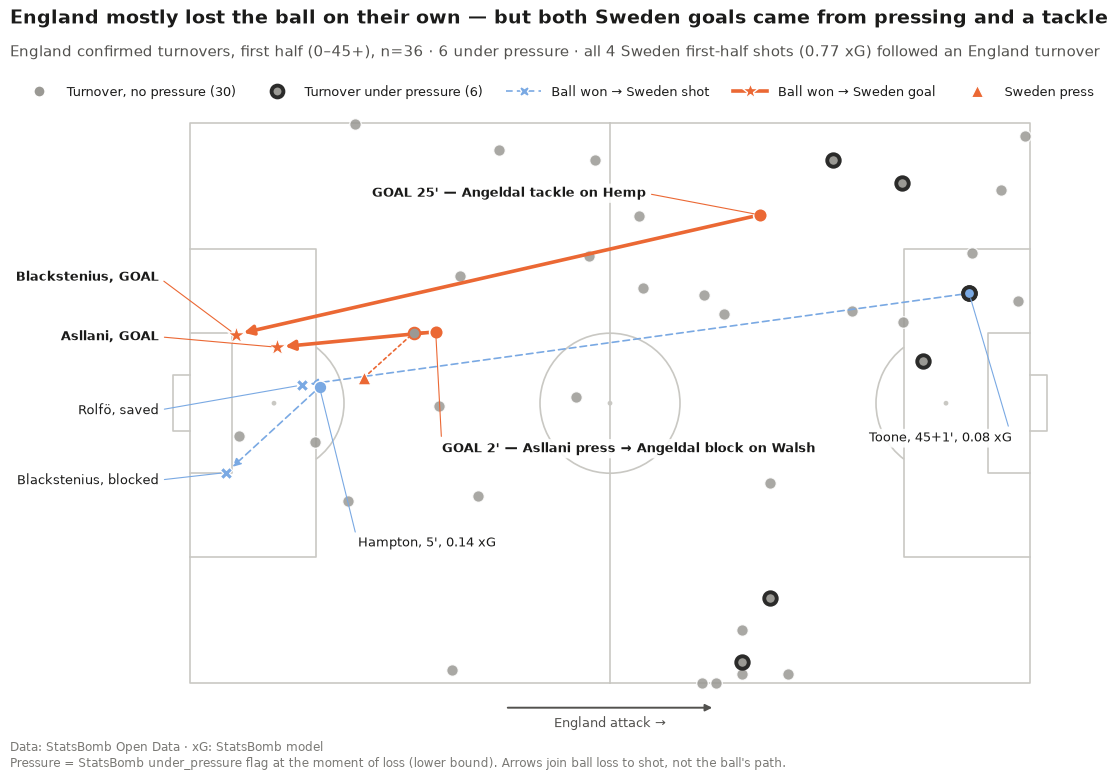

In [4]:
C = P.COLORS
# Pitch shifted right to leave a margin for the shot labels left of England's goal.
pitch, fig, ax = P.make_pitch(figsize=(12, 8), axes_rect=(0.10, 0.07, 0.88, 0.77))

DOT = 70
# Walsh's incomplete pass (2' goal chain) is drawn as its own layer: still a grey turnover dot,
# with a thin orange ring and drawn above the goal arrow.
is_walsh02 = turnovers.id.eq(loss02.id)
assert is_walsh02.sum() == 1 and not turnovers.loc[is_walsh02, "under_pressure"].iloc[0]
walsh02 = turnovers[is_walsh02]
plain = turnovers[~turnovers.under_pressure & ~is_walsh02]
pressed = turnovers[turnovers.under_pressure]

# Layer 1: all confirmed turnovers (grey); pressured ones get a thick dark ring.
sc_plain = pitch.scatter(plain.loss_x, plain.loss_y, ax=ax, s=DOT, color=C["neutral"],
                         edgecolors=C["background"], linewidths=1.0, alpha=0.85, zorder=3)
sc_pressed = pitch.scatter(pressed.loss_x, pressed.loss_y, ax=ax, s=DOT * 1.15, color=C["neutral"],
                           edgecolors=C["neutral_edge"], linewidths=P.PRESSURE_RING_WIDTH, zorder=3)


def arrow(start, end, color, lw=1.8, ls="-"):
    ax.annotate("", xy=end, xytext=start, zorder=4,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls, shrinkA=5, shrinkB=6,
                                mutation_scale=12 if ls != "-" else 14))


def ring(row):
    return C["neutral_edge"] if row.under_pressure else C["background"]


def ring_width(row):
    return P.PRESSURE_RING_WIDTH if row.under_pressure else 1.0


# Layer 2 (secondary): non-goal turnovers that led to a Sweden shot - thinner, lighter, dashed.
S2 = C["accent_secondary"]
non_goal = linked[~linked.led_to_goal]
shot_markers = []
for r in non_goal.itertuples():
    pitch.scatter(r.loss_x, r.loss_y, ax=ax, s=DOT * 1.2, color=S2,
                  edgecolors=ring(r), linewidths=ring_width(r), zorder=5)
    arrow((r.loss_x, r.loss_y), (r.shot_x_eng, r.shot_y_eng), S2, lw=1.2, ls=(0, (4, 2.5)))
    shot_markers.append(pitch.scatter(r.shot_x_eng, r.shot_y_eng, ax=ax, s=DOT * 1.1, marker="X",
                                      color=S2, edgecolors=C["background"],
                                      linewidths=0.8, zorder=5))

# Layer 3 (primary): the two goal sequences (strongest colour, bold).
G = C["goal"]
# 2': press marker, dashed line via Walsh's loss to Angeldal's block on Walsh's pass, arrow block -> shot.
# (Walsh's loss itself stays a grey turnover dot; the ball was won at the block.)
pitch.scatter(press02.x_eng_frame, press02.y_eng_frame, ax=ax, s=DOT * 1.2, marker="^",
              color=G, edgecolors=C["background"], linewidths=0.8, zorder=5)
# Dashed chain: press -> Walsh's loss -> Angeldal's block.
chain02 = [(press02.x_eng_frame, press02.y_eng_frame), (loss02.x_eng_frame, loss02.y_eng_frame),
           (block02.x_eng_frame, block02.y_eng_frame)]
for start, end in zip(chain02[:-1], chain02[1:]):
    ax.annotate("", xy=end, xytext=start, zorder=4,
                arrowprops=dict(arrowstyle="-", color=G, lw=1.2, ls=(0, (2, 2)), shrinkA=5, shrinkB=5))
pitch.scatter(block02.x_eng_frame, block02.y_eng_frame, ax=ax, s=DOT * 1.4, color=G,
              edgecolors=C["background"], linewidths=1.2, zorder=5)
arrow((block02.x_eng_frame, block02.y_eng_frame), (shot02.x_eng_frame, shot02.y_eng_frame), G, lw=2.6)
sc_walsh = pitch.scatter(walsh02.loss_x, walsh02.loss_y, ax=ax, s=DOT, color=C["neutral"],
                         edgecolors=G, linewidths=1.4, zorder=4.5)  # above the arrow (zorder 4)
# 25': Angeldal's tackle on Hemp, arrow -> shot.
pitch.scatter(lost25.x_eng_frame, lost25.y_eng_frame, ax=ax, s=DOT * 1.4, color=G,
              edgecolors=C["background"], linewidths=1.2, zorder=5)
arrow((lost25.x_eng_frame, lost25.y_eng_frame), (shot25.x_eng_frame, shot25.y_eng_frame), G, lw=2.6)
goal_markers = [
    pitch.scatter(s.x_eng_frame, s.y_eng_frame, ax=ax, s=DOT * 2.4, marker="*", color=G,
                  edgecolors=C["background"], linewidths=0.8, zorder=6)
    for s in [shot02, shot25]
]

# Turnover / sequence labels with leader lines, placed in empty areas of the pitch.
LABEL_POS = {"Hampton": (24, 60), "Toone": (97, 45)}
for r in non_goal.itertuples():
    text = f"{surname(r.player_name)}, {fmt_minute(r.display_minute)}, {r.shot_xg:.2f} xG"
    P.label(ax, text, (r.loss_x, r.loss_y), LABEL_POS[surname(r.player_name)], color=S2)
P.label(ax, f"GOAL {fmt_minute(shot02.t // 60 + 1)} — Asllani press → Angeldal block on Walsh",
        (block02.x_eng_frame, block02.y_eng_frame), (36, 46.5), color=G, weight="bold")
P.label(ax, f"GOAL {fmt_minute(shot25.t // 60 + 1)} — Angeldal tackle on Hemp",
        (lost25.x_eng_frame, lost25.y_eng_frame), (26, 10), color=G, weight="bold")

# Shot labels: right-aligned in the margin left of England's goal, ordered top to bottom
# like the shots themselves, so leader lines never cross.
SHOT_OUTCOME_TEXT = {"Goal": "GOAL", "Saved": "saved", "Blocked": "blocked", "Saved to Post": "saved"}
shot_labels = pd.concat([
    non_goal.assign(goal=False)[["shot_player", "shot_outcome", "shot_x_eng", "shot_y_eng", "goal"]],
    pd.DataFrame([dict(shot_player=s.player_name, shot_outcome="Goal", shot_x_eng=s.x_eng_frame,
                       shot_y_eng=s.y_eng_frame, goal=True) for s in [shot02, shot25]]),
]).sort_values("shot_y_eng").reset_index(drop=True)
SHOT_LABEL_X = -4.5
SHOT_LABEL_Y = [22, 30.5, 41, 51]  # one slot per shot, top to bottom
assert len(shot_labels) == len(SHOT_LABEL_Y)
for r, y in zip(shot_labels.itertuples(), SHOT_LABEL_Y):
    P.label(ax, f"{surname(r.shot_player)}, {SHOT_OUTCOME_TEXT[r.shot_outcome]}",
            (r.shot_x_eng, r.shot_y_eng), (SHOT_LABEL_X, y), ha="right",
            color=G if r.goal else S2, weight="bold" if r.goal else "normal")

P.add_attack_arrow(ax, "England attack →")

# Title, legend, footer.
P.add_title(
    fig,
    "England mostly lost the ball on their own — but both Sweden goals came from pressing and a tackle",
    f"England confirmed turnovers, first half (0–45+), n={n_turnovers} · {n_pressure} under pressure · "
    f"all {n_first_half_shots} Sweden first-half shots ({linked_xg:.2f} xG) followed an England turnover",
)
handles = [
    Line2D([], [], ls="", marker="o", ms=8, mfc=C["neutral"], mec=C["background"],
           label=f"Turnover, no pressure ({n_turnovers - n_pressure})"),
    Line2D([], [], ls="", marker="o", ms=8.5, mfc=C["neutral"], mec=C["neutral_edge"],
           mew=P.PRESSURE_RING_WIDTH, label=f"Turnover under pressure ({n_pressure})"),
    Line2D([], [], ls=(0, (4, 2.5)), lw=1.2, color=S2, marker="X", ms=7.5, mec=C["background"],
           label="Ball won → Sweden shot"),
    Line2D([], [], ls="-", lw=2.6, color=G, marker="*", ms=12, mec=C["background"],
           label="Ball won → Sweden goal"),
    Line2D([], [], ls="", marker="^", ms=8.5, mfc=G, mec=C["background"], mew=0.8,
           label="Sweden press"),
]
# One line above the pitch: shrink the legend font (never wrap) until it fits inside the right margin.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for legend_fs in np.arange(P.FONT_SIZES["legend"], 6.9, -0.5):
    leg = fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.04, 0.885), ncol=len(handles),
                     frameon=False, fontsize=legend_fs, handlelength=2.6, columnspacing=1.8)
    right = leg.get_window_extent(renderer).transformed(fig.transFigure.inverted()).x1
    if right <= 0.96:
        break
    leg.remove()
print(f"legend: {len(handles)} entries on one line, font {legend_fs:.1f} pt, right edge at {right:.3f} of figure width")
assert right <= 0.96
P.add_footer(fig, note="Pressure = StatsBomb under_pressure flag at the moment of loss (lower bound). "
                       "Arrows join ball loss to shot, not the ball's path.")

In [5]:
# Check the plotted positions: count markers and confirm Sweden shots sit at the LEFT goal (England's goal).
n_grey = len(sc_plain.get_offsets()) + len(sc_pressed.get_offsets()) + len(sc_walsh.get_offsets())
assert len(sc_walsh.get_offsets()) == 1  # Walsh's 2' loss: one of the 36, drawn with an orange ring
n_ring = len(sc_pressed.get_offsets())
plotted_shots = np.vstack([m.get_offsets() for m in shot_markers + goal_markers])
print(f"grey dots plotted: {n_grey}; under-pressure markers: {n_ring}")
print("Sweden shots as plotted (England frame):")
for (x, y) in plotted_shots:
    print(f"  x'={x:.1f}, y'={y:.1f}")
assert n_grey == 36 and n_ring == 6
assert (plotted_shots[:, 0] < 30).all(), "Sweden shots are not near England's (left) goal"
print("OK: all Sweden shots are within 30 yd of the left goal line (England's goal).")

path = P.save_figure(fig, "01_h1_turnovers")
print("saved:", d.relative_path(path))
plt.show()

grey dots plotted: 36; under-pressure markers: 6
Sweden shots as plotted (England frame):
  x'=5.2, y'=49.9
  x'=16.0, y'=37.4
  x'=12.4, y'=32.0
  x'=6.5, y'=30.2
OK: all Sweden shots are within 30 yd of the left goal line (England's goal).


saved: figures/01_h1_turnovers.png


---
## H2 — Cumulative xG and England's substitutions

**Inputs.** `h2_england_shots`, `h2_cumulative_xg_per_minute`, `h2_summary_game_state_windows`.
The H2 tables hold Sweden's xG only per minute and without scorer names, so Sweden's shot list (exact times,
scorers) is taken from `h5_sweden_shots` (same shot columns) and cross-checked against the per-minute H2 table.

**Time axis.** Minutes *played*, including stoppage time: `elapsed = d.played_minutes(events, 1, 0, period, clock)`,
the same period-by-period logic used for the H2 windows. Period boundaries and substitution events come from
the cached raw events via `src/data.py`. Ticks (0, 15, …, 120) are minutes played, so the end of normal
time sits after 90 because of stoppage time; dotted lines mark the period boundaries.

The penalty shootout (period 5) is excluded.

In [6]:
eng_shots = d.load_processed("h2_england_shots")
swe_shots_all = d.load_processed("h5_sweden_shots")
per_min = d.load_processed("h2_cumulative_xg_per_minute")
h2_windows = d.load_processed("h2_summary_game_state_windows")

events = d.load_events(d.find_match_id())
in_play = events[events.period < d.SHOOTOUT_PERIOD]
subs = d.get_substitutions(events)
period_bounds = in_play.assign(c=d.clock(in_play)).groupby("period").c.agg(["min", "max"])


def elapsed(period: int, clock: float) -> float:
    """Minutes played from kick-off to (period, clock), stoppage time included (src/data.py logic)."""
    return d.played_minutes(events, 1, 0.0, int(period), float(clock))


h2_shots = pd.concat([eng_shots, swe_shots_all], ignore_index=True)
h2_shots = h2_shots[h2_shots.period < d.SHOOTOUT_PERIOD].copy()
h2_shots["clock"] = h2_shots.minute + h2_shots.second / 60
h2_shots["t"] = [elapsed(p, c) for p, c in zip(h2_shots.period, h2_shots.clock)]
h2_shots = h2_shots.sort_values(["t", "index"]).reset_index(drop=True)
END_T = elapsed(period_bounds.index.max(), period_bounds["max"].iloc[-1])
boundaries = {p: elapsed(p, period_bounds.loc[p, "max"]) for p in period_bounds.index[:-1]}
print(f"minutes played to end of extra time: {END_T:.2f}; period ends: "
      + ", ".join(f"P{p} {t:.2f}" for p, t in boundaries.items()))

# Consistency with the per-minute H2 table: per (period, minute) xG must match for both teams.
by_min = h2_shots.pivot_table(index=["period", "minute"], columns="team", values="xg", aggfunc="sum").fillna(0)
pm = per_min.set_index(["period", "minute"])
for team, col in [(d.ENGLAND, "xg_england"), (d.SWEDEN, "xg_sweden")]:
    assert np.allclose(by_min[team].reindex(pm.index, fill_value=0), pm[col]), team
print("OK: shot lists match the per-minute H2 table for both teams")

minutes played to end of extra time: 131.85; period ends: P1 46.62, P2 95.22, P3 113.73
OK: shot lists match the per-minute H2 table for both teams


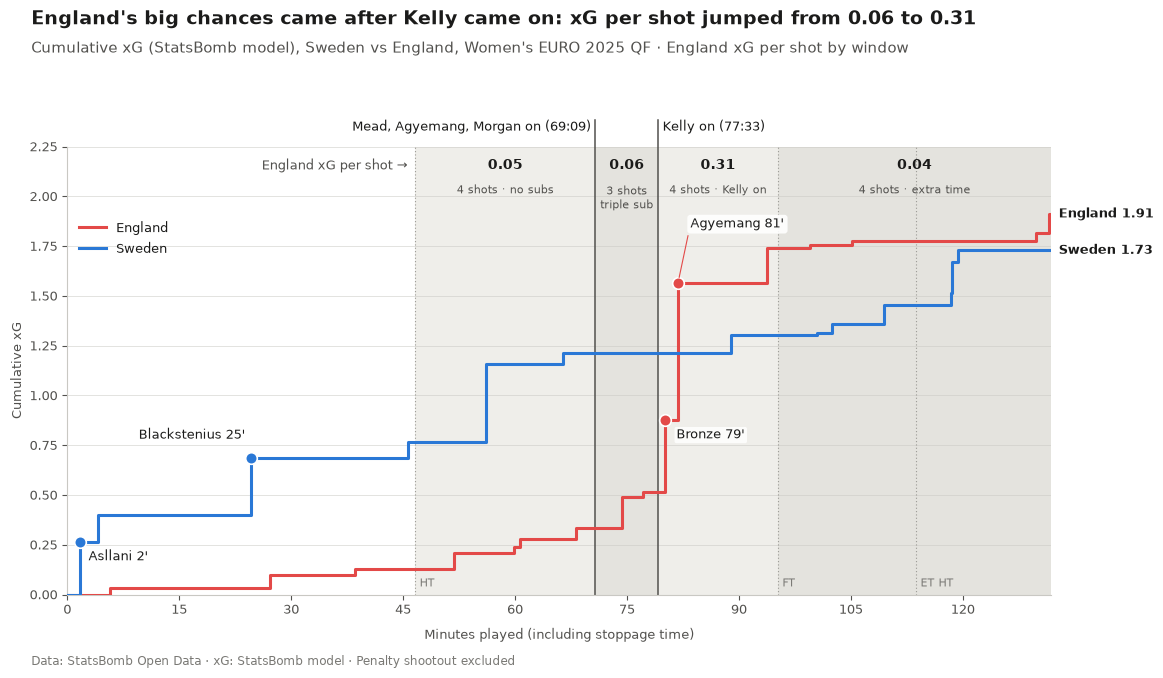

In [7]:
TEAMS = [(d.ENGLAND, "England"), (d.SWEDEN, "Sweden")]
TC = P.TEAM_COLORS

# --- substitution lines from the substitution events --------------------------------------
eng_subs = subs[subs.team == d.ENGLAND].assign(clock=lambda s: s.minute + s.second / 60)
kelly_sub = eng_subs[eng_subs.player_on.str.contains("Kelly")].iloc[0]
triple_subs = eng_subs[(eng_subs.period == kelly_sub.period) & (eng_subs.clock < kelly_sub.clock)]
assert {n.split()[-1] for n in triple_subs.player_on} == {"Mead", "Agyemang", "Morgan"}
first_sub = triple_subs.iloc[0]


def mmss(row) -> str:
    return f"{int(row.minute)}:{int(row.second):02d}"


SUB_LINES = [
    (f"Mead, Agyemang, Morgan on ({mmss(first_sub)})", elapsed(first_sub.period, first_sub.clock)),
    (f"Kelly on ({mmss(kelly_sub)})", elapsed(kelly_sub.period, kelly_sub.clock)),
]

# --- windows from the H2 table (England rows), England xG per shot ------------------------
win = h2_windows[h2_windows.team == "England"].copy()
win["x0"] = [elapsed(p, c) for p, c in zip(win.start_period, win.start_clock)]
win["x1"] = [elapsed(p, c) for p, c in zip(win.end_period, win.end_clock)]
# xg / shots from the table: the stored xg_per_shot is already rounded to 3 decimals
# (0.3055 is stored as 0.305), so formatting it to 2 decimals would round twice.
win["xg_per_shot_exact"] = win.xg / win.shots
assert np.allclose(win.xg_per_shot_exact.round(3), win.xg_per_shot, atol=0.0011)
WINDOW_NAMES = {"W1 control": "no subs", "W2 triple sub": "triple sub",
                "W3 Kelly on": "Kelly on", "W4 extra time": "extra time"}

# --- figure ------------------------------------------------------------------------------
C = P.COLORS
fig = plt.figure(figsize=(12, 7))
ax = fig.add_axes((0.07, 0.13, 0.82, 0.64))
P.style_line_axes(ax)
Y_MAX = 2.25

ax.set_xlim(0, END_T)  # set early so label widths can be measured in data units
renderer = fig.canvas.get_renderer()
window_labels = []
for i, w in enumerate(win.itertuples()):
    ax.axvspan(w.x0, w.x1, color="#efeeea" if i % 2 == 0 else "#e4e3de", zorder=0, lw=0)
    xm = (w.x0 + w.x1) / 2
    ax.text(xm, Y_MAX - 0.06, f"{w.xg_per_shot_exact:.2f}", ha="center", va="top",
            fontsize=P.FONT_SIZES["label"] + 1, fontweight="bold", color=C["text"])
    n = int(w.shots)
    sub = f"{n} shot{'s' if n != 1 else ''} · {WINDOW_NAMES[w.window]}"
    t = ax.text(xm, Y_MAX - 0.19, sub, ha="center", va="top",
                fontsize=P.FONT_SIZES["label"] - 1, color=C["text_secondary"])
    # Too wide for its window: break onto two lines at the separator.
    ext = t.get_window_extent(renderer).transformed(ax.transData.inverted())
    if ext.width > (w.x1 - w.x0) - 0.8:
        t.set_text(sub.replace(" · ", "\n"))
        t.set_multialignment("center")
    window_labels.append(t)
ax.text(win.x0.min() - 1, Y_MAX - 0.06, "England xG per shot →", ha="right", va="top",
        fontsize=P.FONT_SIZES["label"], color=C["text_secondary"])

for p, t in boundaries.items():
    ax.axvline(t, color=C["neutral"], lw=0.8, ls=(0, (1, 2)), zorder=1)
    ax.text(t + 0.6, 0.012, {1: "HT", 2: "FT", 3: "ET HT"}[p], ha="left", va="bottom",
            transform=ax.get_xaxis_transform(), fontsize=P.FONT_SIZES["label"] - 1,
            color=C["text_muted"])

for text, x in SUB_LINES:
    ax.axvline(x, ymax=1.06, color=C["text_secondary"], lw=1.1, zorder=2, clip_on=False)

step_lines, goal_markers = {}, []
for team, label in TEAMS:
    s = h2_shots[h2_shots.team == team]
    xs = np.r_[0, s.t, END_T]
    ys = np.r_[0, s.xg.cumsum(), s.xg.sum()]
    (step_lines[label],) = ax.step(xs, ys, where="post", color=TC[label], lw=2.2, zorder=3, label=label)
    ax.text(END_T + 1, ys[-1], f"{label} {ys[-1]:.2f}", ha="left", va="center",
            fontsize=P.FONT_SIZES["label"] + 0.5, fontweight="bold", color=C["text"])
    g = s.assign(cum=s.xg.cumsum())[s.is_goal]
    goal_markers.append(ax.scatter(g.t, g.cum, s=70, color=TC[label], edgecolors=C["background"],
                                   linewidths=1.2, zorder=5))

# Goal labels (offsets in points, chosen to avoid the lines and each other).
GOAL_OFFSETS = {"Asllani": (6, -5), "Blackstenius": (-4, 12), "Bronze": (8, -6), "Agyemang": None}
AGYEMANG_LABEL_XY = (83.5, 1.86)  # free space above England's line, below the window labels
goal_rows = []
for team, label in TEAMS:
    s = h2_shots[h2_shots.team == team].assign(cum=lambda x: x.xg.cumsum())
    goal_rows.append(s[s.is_goal].assign(label=label))
goal_rows = pd.concat(goal_rows)
for r in goal_rows.itertuples():
    name = r.player_name.split()[-1]
    text = f"{name} {r.display_minute}'"
    if GOAL_OFFSETS[name] is None:  # placed in free space with a leader line
        P.label(ax, text, (r.t, r.cum), AGYEMANG_LABEL_XY, color=P.TEAM_COLORS[r.label])
        continue
    dx, dy = GOAL_OFFSETS[name]
    ax.annotate(text, (r.t, r.cum), xytext=(dx, dy), textcoords="offset points",
                ha="right" if dx < 0 else "left", va="bottom" if dy > 0 else "top",
                fontsize=P.FONT_SIZES["label"], color=C["text"], zorder=6,
                bbox=dict(boxstyle="round,pad=0.15", fc=C["background"], ec="none", alpha=0.85))

# Substitution labels above the plot, at the top of each (extended) line: the first to the
# left of its line, the second to the right, so the two never collide.
for (text, x), ha, dx in zip(SUB_LINES, ["right", "left"], [-0.6, 0.6]):
    ax.text(x + dx, 1.06, text, ha=ha, va="top", transform=ax.get_xaxis_transform(),
            fontsize=P.FONT_SIZES["label"], color=C["text"], clip_on=False)

ax.set_xlim(0, END_T)
ax.set_ylim(0, Y_MAX)
ax.set_xticks(range(0, 121, 15))
ax.set_xlabel("Minutes played (including stoppage time)", fontsize=P.FONT_SIZES["label"],
              color=C["text_secondary"], labelpad=8)
ax.set_ylabel("Cumulative xG", fontsize=P.FONT_SIZES["label"], color=C["text_secondary"])
ax.legend(handles=list(step_lines.values()), loc="upper left", bbox_to_anchor=(0.0, 0.86), frameon=False,
          fontsize=P.FONT_SIZES["legend"])

P.add_title(
    fig,
    "England's big chances came after Kelly came on: xG per shot jumped from "
    f"{win.loc[win.window == 'W2 triple sub', 'xg_per_shot_exact'].iloc[0]:.2f} to "
    f"{win.loc[win.window == 'W3 Kelly on', 'xg_per_shot_exact'].iloc[0]:.2f}",
    "Cumulative xG (StatsBomb model), Sweden vs England, Women's EURO 2025 QF · England xG per shot by window",
)
P.add_footer(fig, "Data: StatsBomb Open Data · xG: StatsBomb model · Penalty shootout excluded")

In [8]:
# Built-in checks.
# 1) Final cumulative xG per team == sum of shot xG in periods 1-4 (and == the per-minute H2 table).
for team, label in TEAMS:
    line_final = step_lines[label].get_ydata()[-1]
    shots_sum = h2_shots.loc[h2_shots.team == team, "xg"].sum()
    table_final = per_min[f"cum_xg_{label.lower()}"].iloc[-1]
    assert np.isclose(line_final, shots_sum) and np.isclose(line_final, table_final), label
    print(f"{label}: final cumulative xG {line_final:.3f} (shots periods 1-4: {shots_sum:.3f}, "
          f"per-minute table: {table_final:.3f})")

# 2) All four goals are plotted, with the expected scorers and minutes.
n_goals_plotted = sum(len(m.get_offsets()) for m in goal_markers)
plotted = sorted(f"{r.player_name.split()[-1]} {r.display_minute}'" for r in goal_rows.itertuples())
print(f"goals plotted: {n_goals_plotted} -> {plotted}")
assert n_goals_plotted == 4
assert set(plotted) == {"Asllani 2'", "Blackstenius 25'", "Bronze 79'", "Agyemang 81'"}

# 4) Window labels (shot count · name) do not overlap each other and stay inside the plot.
fig.draw_without_rendering()
boxes = [t.get_window_extent() for t in window_labels]
for a, b in zip(boxes[:-1], boxes[1:]):
    assert a.x1 < b.x0, "window labels overlap"
assert boxes[-1].x1 <= ax.get_window_extent().x1
print("window labels: " + " | ".join(t.get_text().replace("\n", " / ") for t in window_labels) + " - no overlaps")

# 3) Substitution lines sit exactly at the substitution events (and at the window boundaries).
line_x = sorted(l.get_xdata()[0] for l in ax.lines if l.get_color() == C["text_secondary"])
event_x = sorted([elapsed(first_sub.period, first_sub.clock), elapsed(kelly_sub.period, kelly_sub.clock)])
window_x = sorted([win.loc[win.window == "W2 triple sub", "x0"].iloc[0],
                   win.loc[win.window == "W3 Kelly on", "x0"].iloc[0]])
assert np.allclose(line_x, event_x) and np.allclose(line_x, window_x)
print(f"substitution lines at minutes played {line_x[0]:.2f} (clock {mmss(first_sub)}) and "
      f"{line_x[1]:.2f} (clock {mmss(kelly_sub)}) - match the substitution events and window edges")

path = P.save_figure(fig, "02_h2_cumulative_xg")
print("saved:", d.relative_path(path))
plt.show()

England: final cumulative xG 1.911 (shots periods 1-4: 1.911, per-minute table: 1.911)
Sweden: final cumulative xG 1.728 (shots periods 1-4: 1.728, per-minute table: 1.728)
goals plotted: 4 -> ["Agyemang 81'", "Asllani 2'", "Blackstenius 25'", "Bronze 79'"]
window labels: 4 shots · no subs | 3 shots / triple sub | 4 shots · Kelly on | 4 shots · extra time - no overlaps
substitution lines at minutes played 70.77 (clock 69:09) and 79.17 (clock 77:33) - match the substitution events and window edges


saved: figures/02_h2_cumulative_xg.png


---
## H3 — England's pass networks before the substitutions and after Kelly came on

**Inputs.** `h3_england_completed_passes`, `h3_england_average_positions`, `h3_england_pass_pairs`,
`h3_segment_summary`, plus `h3_england_formations` for shirt numbers. All are filtered exactly as in notebook 02:
completed passes, **open play only** (`set_piece == False`), one stable-lineup segment per panel.

* **Left:** segment 1, 0–69:09 (starting XI, before any substitution).
* **Right:** segment 5, 77:33–103:42 (after Kelly came on).

**Node position.** `h3_england_average_positions` stores the mean location of the passes a player *made* only.
The chart uses the mean location of passes **made and received**, so it is aggregated here from the prepared
pass table (pass start for the passer, pass end for the receiver). The made-only mean is recomputed from the same
rows and checked against the stored table, so both use identical inputs. The evidence table reports both.

**Not shown:** segments 2–3 (69:09–69:29, a few seconds each during the triple substitution, dropped in notebook 02),
segment 4 (69:29–77:33, outside both H3 windows, so not in the prepared tables), segment 6 (103:42–105:00,
0 completed passes) and segment 7 (105:00–end, 17 passes, too few for a network).

In [9]:
h3_passes = d.load_processed("h3_england_completed_passes")
h3_positions = d.load_processed("h3_england_average_positions")
h3_pairs = d.load_processed("h3_england_pass_pairs")
h3_segments = d.load_processed("h3_segment_summary").set_index("segment")
h3_formations = d.load_processed("h3_england_formations")

H3_SEGMENTS = [1, 5]
net_passes = h3_passes[~h3_passes.set_piece]
jersey = h3_formations.drop_duplicates("player").set_index("player").jersey_number


def surname(name: str) -> str:
    return name.split()[-1]


def mmss_clock(clock: float) -> str:
    total = round(clock * 60)
    return f"{total // 60}:{total % 60:02d}"


def network_nodes(segment: int) -> pd.DataFrame:
    """One row per player: mean location of passes made and received, passes made (open play)."""
    s = net_passes[net_passes.segment == segment]
    made = s[["player", "pass_x", "pass_y"]].set_axis(["player", "x", "y"], axis=1)
    received = s[["pass_recipient", "pass_end_x", "pass_end_y"]].set_axis(["player", "x", "y"], axis=1)
    nodes = pd.concat([made, received]).groupby("player")[["x", "y"]].mean()
    table = h3_positions[h3_positions.segment == segment].set_index("player")
    # Same inputs as the stored table: the made-only mean must reproduce avg_x / avg_y exactly.
    made_mean = made.groupby("player")[["x", "y"]].mean()
    assert np.allclose(made_mean.loc[table.index, "x"], table.avg_x)
    assert np.allclose(made_mean.loc[table.index, "y"], table.avg_y)
    nodes = nodes.join(table[["player_name", "position", "avg_x", "avg_y", "n_passes", "n_received"]])
    nodes["jersey"] = jersey.reindex(nodes.index).astype(int)
    nodes["surname"] = nodes.player_name.map(surname)
    return nodes


def network_edges(segment: int) -> pd.DataFrame:
    """Undirected passer-receiver pairs (both directions combined), with the segment threshold applied."""
    p = h3_pairs[h3_pairs.segment == segment]
    key = [tuple(sorted(ab)) for ab in zip(p.passer, p.recipient)]
    edges = p.assign(a=[k[0] for k in key], b=[k[1] for k in key]).groupby(["a", "b"]).n_passes.sum()
    edges = edges.rename("n").reset_index()
    return edges[edges.n >= h3_segments.loc[segment, "edge_threshold"]].reset_index(drop=True)


nodes = {seg: network_nodes(seg) for seg in H3_SEGMENTS}
edges = {seg: network_edges(seg) for seg in H3_SEGMENTS}
for seg in H3_SEGMENTS:
    r = h3_segments.loc[seg]
    print(f"segment {seg} ({mmss_clock(r.start_clock)}-{mmss_clock(r.end_clock)}): {len(nodes[seg])} players, "
          f"{int(nodes[seg].n_passes.sum())} completed open-play passes (table: {r.completed_passes}), "
          f"{len(edges[seg])} links with >= {r.edge_threshold} passes")

segment 1 (0:00-69:09): 11 players, 272 completed open-play passes (table: 272), 35 links with >= 3 passes
segment 5 (77:33-103:42): 11 players, 76 completed open-play passes (table: 76), 16 links with >= 2 passes


### Orientation check

England attack left → right in both panels. On mplsoccer's StatsBomb pitch y grows downwards, so England's
**left** flank (small y) must be drawn at the **top**. In segment 1 Greenwood (left back) must be above Bronze
(right back) on the drawn pitch. The check runs on a pitch drawn with the same helper as the chart.

In [10]:
_fig = plt.figure(figsize=(6, 4))
_, _ax = P.add_pitch(_fig, (0, 0, 1, 1))
n1 = nodes[1]
gw_screen = _ax.transData.transform((n1.loc["Alex Greenwood", "x"], n1.loc["Alex Greenwood", "y"]))
br_screen = _ax.transData.transform((n1.loc["Lucy Bronze", "x"], n1.loc["Lucy Bronze", "y"]))
plt.close(_fig)
assert n1.loc["Alex Greenwood", "position"] == "Left Back" and n1.loc["Lucy Bronze", "position"] == "Right Back"
orientation_ok = gw_screen[1] > br_screen[1]  # screen y grows upwards: larger = higher on the drawn pitch
assert orientation_ok, "flanks reversed: fix the y-axis before drawing"
print(f"OK: Greenwood (LB, y={n1.loc['Alex Greenwood', 'y']:.1f}) drawn at the top, "
      f"Bronze (RB, y={n1.loc['Lucy Bronze', 'y']:.1f}) at the bottom - England's left is on top, "
      "no axis change needed")

OK: Greenwood (LB, y=12.6) drawn at the top, Bronze (RB, y=73.0) at the bottom - England's left is on top, no axis change needed


### Evidence table

Positions in yards (StatsBomb 120 × 80, England attacking towards x = 120, y = 0 is England's left touchline,
y = 40 the centre line). Main values use the chart's definition (passes made and received); the made-only
values from the stored table are shown for robustness. Goalkeepers are excluded from "deepest outfield players".

Criteria used for the verdicts (set before reading the result):
* **(a)** Bronze's average x at least 5 yd higher after Kelly came on, and still on the right half (y > 40).
* **(b)** Kelly on the left third (y < 26.7) **and** the most passes received of any outfield player in segment 5.
* **(c)** James within 10 yd of Walsh.
* **(d)** a clear back line of three: the 4th-deepest outfield player at least 8 yd ahead of the 3rd.

In [11]:
A_MIN_DX, C_MAX_DIST, D_MIN_GAP, LEFT_THIRD_Y = 5.0, 10.0, 8.0, 80 / 3


def evidence(seg: int, xcol: str, ycol: str) -> dict:
    n = nodes[seg]
    out = {f"x {s}": n.loc[p, xcol] for p, s in [("Lucy Bronze", "Bronze"), ("Lauren James", "James"),
                                                 ("Keira Walsh", "Walsh"), ("Chloe Kelly", "Kelly")]
           if p in n.index}
    out.update({f"y {s}": n.loc[p, ycol] for p, s in [("Chloe Kelly", "Kelly"), ("Lucy Bronze", "Bronze")]
                if p in n.index})
    outfield = n[n.position != "Goalkeeper"].sort_values(xcol)
    out["deepest 3"] = ", ".join(f"{s} {x:.1f}" for s, x in zip(outfield.surname[:3], outfield[xcol][:3]))
    out["4th deepest"] = f"{outfield.surname.iloc[3]} {outfield[xcol].iloc[3]:.1f}"
    out["gap 3rd-4th"] = outfield[xcol].iloc[3] - outfield[xcol].iloc[2]
    j, w = n.loc["Lauren James"], n.loc["Keira Walsh"]
    out["James-Walsh dist"] = float(np.hypot(j[xcol] - w[xcol], j[ycol] - w[ycol]))
    return out


ev = pd.DataFrame({
    (f"{mmss_clock(h3_segments.loc[seg, 'start_clock'])}-{mmss_clock(h3_segments.loc[seg, 'end_clock'])}", lab):
        evidence(seg, xc, yc)
    for seg in H3_SEGMENTS for lab, xc, yc in [("made+received", "x", "y"), ("made only", "avg_x", "avg_y")]
})
print(ev.map(lambda v: f"{v:.1f}" if isinstance(v, float) else ("-" if pd.isna(v) else v)).to_string())

                                                0:00-69:09                                                                         77:33-103:42                                          
                                             made+received                                  made only                             made+received                                 made only
x Bronze                                              61.3                                       53.8                                      74.9                                      62.5
x James                                               77.2                                       76.5                                      65.1                                      63.8
x Walsh                                               60.0                                       62.4                                      50.9                                      54.1
y Bronze                                              73.0            

In [12]:
n1, n5 = nodes[1], nodes[5]
e1, e5 = evidence(1, "x", "y"), evidence(5, "x", "y")
outfield5 = n5[n5.position != "Goalkeeper"]
top_receiver = outfield5.n_received.idxmax()
kelly_rank = int(outfield5.n_received.rank(ascending=False, method="min")["Chloe Kelly"])
bronze_dx = e5["x Bronze"] - e1["x Bronze"]
james_dx = e5["x James"] - e1["x James"]

verdict = {
    "a": bronze_dx >= A_MIN_DX and e5["y Bronze"] > 40,
    "b": e5["y Kelly"] < LEFT_THIRD_Y and top_receiver == "Chloe Kelly",
    "c": e5["James-Walsh dist"] <= C_MAX_DIST,
    "d": e5["gap 3rd-4th"] >= D_MIN_GAP,
}
print(f"(a) Bronze pushed higher on the right: {'SUPPORTED' if verdict['a'] else 'NOT SUPPORTED'} - her average x "
      f"rose {bronze_dx:+.1f} yd ({e1['x Bronze']:.1f} -> {e5['x Bronze']:.1f}) and she stayed right of centre, "
      f"but narrower (y {e1['y Bronze']:.1f} -> {e5['y Bronze']:.1f}, i.e. {80 - e5['y Bronze']:.1f} yd "
      "from the right touchline).")
print(f"(b) Kelly as a main outlet on the left: {'SUPPORTED' if verdict['b'] else 'NOT SUPPORTED'} - she was "
      f"England's left-sided attacker (y {e5['y Kelly']:.1f}, x {e5['x Kelly']:.1f}), but received "
      f"{n5.loc['Chloe Kelly', 'n_received']} of {h3_segments.loc[5, 'completed_passes']} passes, rank "
      f"{kelly_rank} among outfield players (most: {surname(top_receiver)} {outfield5.n_received.max()}).")
print(f"(c) James dropping next to Walsh: {'SUPPORTED' if verdict['c'] else 'NOT SUPPORTED'} - James dropped "
      f"{-james_dx:.1f} yd deeper ({e1['x James']:.1f} -> {e5['x James']:.1f}), but stayed "
      f"{e5['James-Walsh dist']:.1f} yd from Walsh (was {e1['James-Walsh dist']:.1f}), "
      f"{e5['x James'] - e5['x Walsh']:.1f} yd ahead of her.")
print(f"(d) a back three in possession: {'SUPPORTED' if verdict['d'] else 'NOT SUPPORTED'} - the three deepest "
      f"outfield players ({e5['deepest 3']}) are only {e5['gap 3rd-4th']:.1f} yd behind the 4th "
      f"({e5['4th deepest']}); a clear back three needs >= {D_MIN_GAP:.0f} yd.")

(a) Bronze pushed higher on the right: SUPPORTED - her average x rose +13.5 yd (61.3 -> 74.9) and she stayed right of centre, but narrower (y 73.0 -> 55.5, i.e. 24.5 yd from the right touchline).
(b) Kelly as a main outlet on the left: NOT SUPPORTED - she was England's left-sided attacker (y 25.7, x 79.4), but received 10 of 76 passes, rank 3 among outfield players (most: Greenwood 12).
(c) James dropping next to Walsh: NOT SUPPORTED - James dropped 12.1 yd deeper (77.2 -> 65.1), but stayed 15.4 yd from Walsh (was 17.7), 14.2 yd ahead of her.
(d) a back three in possession: NOT SUPPORTED - the three deepest outfield players (Williamson 34.7, Morgan 43.7, Walsh 50.9) are only 5.2 yd behind the 4th (Greenwood 56.1); a clear back three needs >= 8 yd.


**Sensitivity check (not on the chart).** With passes-made-only positions (the stored
`h3_england_average_positions` table), segment 1 shows a back-three-like shape: Carter 40.3, Williamson 43.8 and
Bronze 53.8 are the three deepest outfield players, with an 8.6 yd gap to the 4th (Walsh 62.4). With made+received
positions that gap is only 1.3 yd (Walsh moves into the deepest three). After Kelly came on, neither method shows
a back three (gaps 5.2 / 4.4 yd). So any back-three-like shape points to the starting XI, not to the change. The
chart keeps the made+received method.

### Title

Written from the verdicts above: it states only what the evidence supports (Bronze higher; James deeper, which
is measured, not claimed as "next to Walsh") and the unsupported back three is stated as absent, so 3-4-3 is not
mentioned. The yard values stay in the evidence table, not in the title.

In [13]:
assert verdict["a"] and not verdict["d"], "title claims no longer match the evidence - rewrite it"
H3_TITLE = ("After Kelly came on, Bronze pushed up and James dropped deeper — "
            "average positions show no back three")
assert bronze_dx > 0 and james_dx < 0  # "pushed up" / "dropped deeper"
print(H3_TITLE)

After Kelly came on, Bronze pushed up and James dropped deeper — average positions show no back three


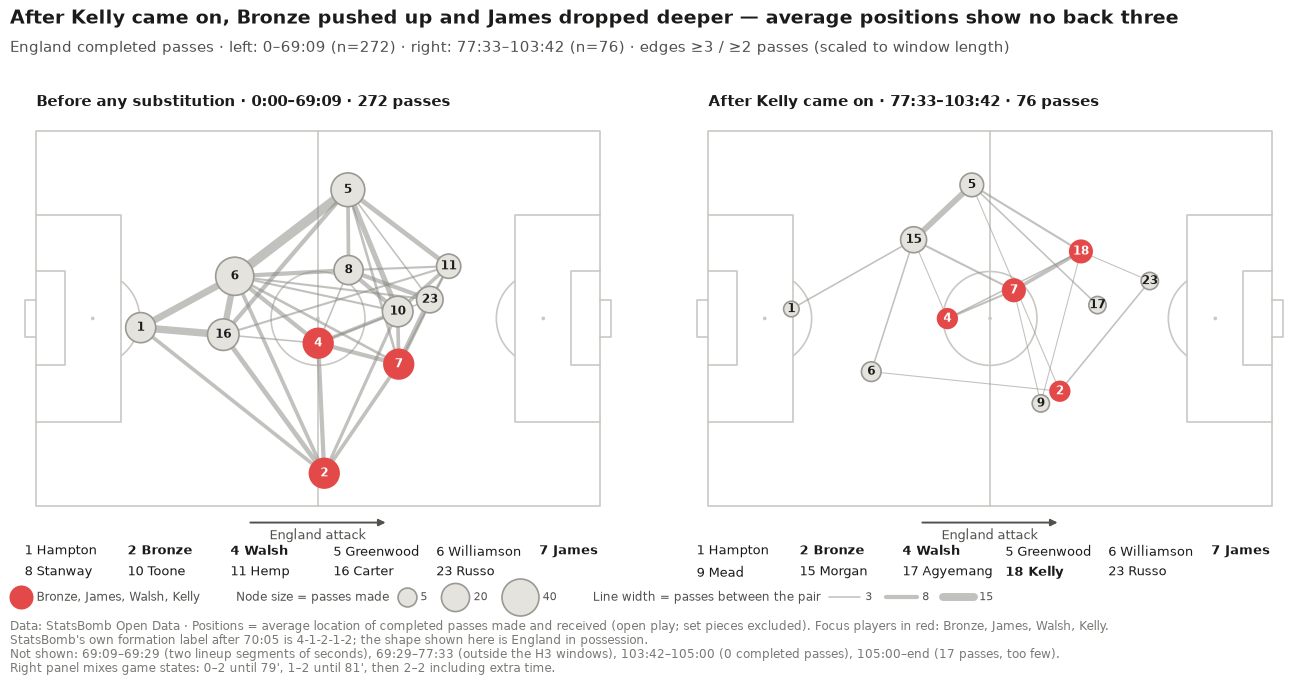

In [14]:
HIGHLIGHT = ["Lucy Bronze", "Chloe Kelly", "Lauren James", "Keira Walsh"]
C = P.COLORS
ENG = P.TEAM_COLORS["England"]
NODE_MUTED, NODE_MUTED_EDGE, EDGE_COLOR = "#e4e3de", C["neutral"], "#8f8e89"

# One scale for both panels: node area and edge width are linear in the pass count.
NODE_SIZE_BASE, NODE_SIZE_PER_PASS = 110, 15
EDGE_LW_PER_PASS = 0.38


def node_size(n):
    return NODE_SIZE_BASE + NODE_SIZE_PER_PASS * np.asarray(n, dtype=float)


def edge_lw(n):
    return EDGE_LW_PER_PASS * np.asarray(n, dtype=float)


fig = plt.figure(figsize=(14, 7))
PANEL_RECTS = {1: (0.035, 0.215, 0.45, 0.59), 5: (0.515, 0.215, 0.45, 0.59)}
PANEL_HEADS = {1: "Before any substitution", 5: "After Kelly came on"}
drawn = {}
for seg in H3_SEGMENTS:
    pitch, ax = P.add_pitch(fig, PANEL_RECTS[seg])
    n, e, r = nodes[seg], edges[seg], h3_segments.loc[seg]
    xy = n[["x", "y"]]
    lws = edge_lw(e.n)
    for row, lw in zip(e.itertuples(), lws):
        ax.plot(xy.loc[[row.a, row.b], "x"], xy.loc[[row.a, row.b], "y"], lw=lw, color=EDGE_COLOR,
                alpha=0.55, zorder=2, solid_capstyle="round")
    hl = n.index.isin(HIGHLIGHT)
    sizes = node_size(n.n_passes)
    sc = pitch.scatter(n.x, n.y, s=sizes, ax=ax, zorder=3, linewidths=1.2,
                       c=list(np.where(hl, ENG, NODE_MUTED)), edgecolors=list(np.where(hl, ENG, NODE_MUTED_EDGE)))
    for p, row in n.iterrows():
        ax.text(row.x, row.y, str(row.jersey), ha="center", va="center", zorder=4,
                fontsize=P.FONT_SIZES["label"] - 0.5, fontweight="bold",
                color=C["background"] if p in HIGHLIGHT else C["text"])
    P.add_attack_arrow(ax, "England attack")
    ax.text(0, -4.5, f"{PANEL_HEADS[seg]} · {mmss_clock(r.start_clock)}–{mmss_clock(r.end_clock)} · "
            f"{r.completed_passes} passes", ha="left", va="bottom", fontsize=P.FONT_SIZES["subtitle"],
            fontweight="bold", color=C["text"], clip_on=False)
    # Key below the pitch: shirt number -> surname, highlighted players in bold.
    key = n.sort_values("jersey")
    bbox = ax.get_position()
    entries = [(f"{row.jersey} {row.surname}", p in HIGHLIGHT) for p, row in key.iterrows()]
    for line_i, chunk in enumerate([entries[:6], entries[6:]]):
        x = bbox.x0 + 0.005
        for text, bold in chunk:
            t = fig.text(x, bbox.y0 - 0.015 - 0.03 * line_i, text, ha="left", va="top",
                         fontsize=P.FONT_SIZES["label"], color=C["text"],
                         fontweight="bold" if bold else "normal")
            x += 0.0735
    drawn[seg] = dict(ax=ax, scatter=sc, sizes=sizes, n_passes=n.n_passes.to_numpy(),
                      edge_n=e.n.to_numpy(), edge_lw=lws)

# Scale key (same scale in both panels): one row in the band between the player keys and the footer.
# Items are laid out left to right with measured widths, so markers and text never collide.
KEY_Y, KEY_FS, GAP_PT = 0.125, P.FONT_SIZES["label"] - 0.5, 6
renderer = fig.canvas.get_renderer()
pt = 1 / (72 * fig.get_figwidth())  # one point in figure-width fractions
cursor = 0.04


def key_text(text, gap_after=GAP_PT, size=KEY_FS):
    global cursor
    t = fig.text(cursor, KEY_Y, text, ha="left", va="center", fontsize=size, color=C["text_secondary"])
    cursor += t.get_window_extent(renderer).width / fig.bbox.width + gap_after * pt
    return t


def key_node(n_pass, color, edge):
    global cursor
    diameter_pt = np.sqrt(node_size(n_pass))
    fig.add_artist(Line2D([cursor + diameter_pt / 2 * pt], [KEY_Y], marker="o", markersize=diameter_pt,
                          markerfacecolor=color, markeredgecolor=edge, markeredgewidth=1.2, ls="none"))
    cursor += (diameter_pt + 3) * pt


def key_edge(n_pass, length_pt=22):
    global cursor
    fig.add_artist(Line2D([cursor, cursor + length_pt * pt], [KEY_Y, KEY_Y], lw=float(edge_lw(n_pass)),
                          color=EDGE_COLOR, alpha=0.55, solid_capstyle="round"))
    cursor += (length_pt + 4) * pt


key_node(10, ENG, ENG)
key_text("Bronze, James, Walsh, Kelly", gap_after=26)
key_text("Node size = passes made")
for k in [5, 20, 40]:
    key_node(k, NODE_MUTED, NODE_MUTED_EDGE)
    key_text(str(k), gap_after=10, size=KEY_FS - 0.5)
cursor += 16 * pt
key_text("Line width = passes between the pair")
for k in [3, 8, 15]:
    key_edge(k)
    key_text(str(k), gap_after=10, size=KEY_FS - 0.5)
KEY_RIGHT = cursor

# Game state in the right panel, from the goal rows of the shot tables (H2 section).
goals = h2_shots[h2_shots.is_goal].sort_values("t")
eng_goals = goals[goals.team == d.ENGLAND]
assert len(eng_goals) == 2 and (goals[goals.team == d.SWEDEN].display_minute < 77).all()
GAME_STATE_LINE = (f"Right panel mixes game states: 0–2 until {eng_goals.display_minute.iloc[0]}', "
                   f"1–2 until {eng_goals.display_minute.iloc[1]}', then 2–2 including extra time.")

s1, s5 = h3_segments.loc[1], h3_segments.loc[5]
P.add_title(
    fig, H3_TITLE,
    f"England completed passes · left: {mmss_clock(s1.start_clock).split(':')[0]}–{mmss_clock(s1.end_clock)} "
    f"(n={s1.completed_passes}) · right: {mmss_clock(s5.start_clock)}–{mmss_clock(s5.end_clock)} "
    f"(n={s5.completed_passes}) · edges ≥{s1.edge_threshold} / ≥{s5.edge_threshold} passes "
    "(scaled to window length)",
)
P.add_footer(
    fig,
    "Data: StatsBomb Open Data · Positions = average location of completed passes made and received "
    "(open play; set pieces excluded). Focus players in red: Bronze, James, Walsh, Kelly.",
    "StatsBomb's own formation label after 70:05 is 4-1-2-1-2; the shape shown here is England in possession.\n"
    "Not shown: 69:09–69:29 (two lineup segments of seconds), 69:29–77:33 (outside the H3 windows), "
    "103:42–105:00 (0 completed passes), 105:00–end (17 passes, too few).\n" + GAME_STATE_LINE,
)

In [15]:
# Built-in checks.
for seg in H3_SEGMENTS:
    dr, r = drawn[seg], h3_segments.loc[seg]
    # 1) Completed passes per panel = table (272 / 76): node pass counts and pair counts both add up.
    assert dr["n_passes"].sum() == r.completed_passes
    assert h3_pairs[h3_pairs.segment == seg].n_passes.sum() == r.completed_passes
    # 2) 11 nodes per panel.
    assert len(dr["scatter"].get_offsets()) == 11
    # 3) Every drawn edge meets the segment threshold, and all qualifying pairs are drawn.
    assert (dr["edge_n"] >= r.edge_threshold).all() and len(dr["edge_n"]) == len(edges[seg])
    print(f"segment {seg}: {dr['n_passes'].sum()} passes (table {r.completed_passes}), "
          f"{len(dr['scatter'].get_offsets())} nodes, {len(dr['edge_n'])} edges, "
          f"min edge {dr['edge_n'].min()} >= threshold {r.edge_threshold}")

# 4) Node and edge scales identical across panels: every drawn size / width is the same linear function.
for seg in H3_SEGMENTS:
    dr = drawn[seg]
    assert np.allclose(dr["scatter"].get_sizes(), node_size(dr["n_passes"]))
    assert np.allclose(dr["edge_lw"], edge_lw(dr["edge_n"]))
size_per_pass = {seg: np.polyfit(drawn[seg]["n_passes"], drawn[seg]["scatter"].get_sizes(), 1)
                 for seg in H3_SEGMENTS}
lw_per_pass = {seg: drawn[seg]["edge_lw"] / drawn[seg]["edge_n"] for seg in H3_SEGMENTS}
assert np.allclose(size_per_pass[1], size_per_pass[5])
assert np.allclose(np.r_[lw_per_pass[1], lw_per_pass[5]], EDGE_LW_PER_PASS)
print(f"scales identical: node area = {size_per_pass[1][1]:.0f} + {size_per_pass[1][0]:.0f} x passes in both "
      f"panels; edge width = {EDGE_LW_PER_PASS} x passes in both panels")

# 5) Orientation check passed; highlighted players present as expected (Kelly only on the right).
assert orientation_ok
assert set(HIGHLIGHT) <= set(nodes[5].index) and "Chloe Kelly" not in nodes[1].index
assert KEY_RIGHT < 0.80, "scale key runs into the logo area"
print("orientation check passed: England's left flank (Greenwood) on top, right flank (Bronze) at the bottom")

path = P.save_figure(fig, "03_h3_pass_networks")
print("saved:", d.relative_path(path))
plt.show()

segment 1: 272 passes (table 272), 11 nodes, 35 edges, min edge 3 >= threshold 3
segment 5: 76 passes (table 76), 11 nodes, 16 edges, min edge 2 >= threshold 2
scales identical: node area = 110 + 15 x passes in both panels; edge width = 0.38 x passes in both panels
orientation check passed: England's left flank (Greenwood) on top, right flank (Bronze) at the bottom


saved: figures/03_h3_pass_networks.png


---
## H4 — England's crossing before and after Kelly came on

**Question.** After Kelly came on (77:33), did England's crossing change, and did it create the goals?

**Inputs.** `h4_england_crosses` (every England pass with StatsBomb's `pass_cross` flag, periods 1–4) and
`h4_summary_before_after_77` (used only as a cross-check). Minutes played for the per-90 rates come from the cached
raw events with `d.played_minutes`, the same helper as in H2. The split point is Kelly's substitution event.

* **Open play** = `pass_type` is not a set piece (`Free Kick`, `Corner`, `Throw-in`, `Goal Kick`, `Kick Off`).
  `Recovery` passes count as open play. Set-piece crosses are reported separately and are not on the chart.
* **Windows:** 0–77:33 (before Kelly), 77:33–end of the second half (Kelly on), and extra time (reported only).
* **Flank** comes from the table (`left` = y < 40, England's left).

In [16]:
h4_crosses = d.load_processed("h4_england_crosses")
h4_summary = d.load_processed("h4_summary_before_after_77")
H4_SET_PIECES = ["Free Kick", "Corner", "Throw-in", "Goal Kick", "Kick Off"]

h4_crosses["set_piece"] = h4_crosses.pass_type.isin(H4_SET_PIECES)
h4_crosses["clock"] = h4_crosses.minute + h4_crosses.second / 60
KELLY_CLOCK = kelly_sub.minute + kelly_sub.second / 60  # substitution event (H2 section)
h4_crosses["h4_window"] = np.select(
    [h4_crosses.period >= 3, (h4_crosses.period == 2) & (h4_crosses.clock >= KELLY_CLOCK)],
    ["extra time", "after"], default="before",
)
assert (h4_crosses.after_77 == (h4_crosses.h4_window != "before")).all()  # same split as the table

set_piece_crosses = h4_crosses[h4_crosses.set_piece]
print(f"Set pieces flagged as crosses: {len(set_piece_crosses)} "
      f"({set_piece_crosses.pass_type.value_counts().to_dict()}); corners in the table: "
      f"{int((h4_crosses.pass_type == 'Corner').sum())}")
print(set_piece_crosses[["period", "minute", "second", "player_name", "pass_type", "completed",
                         "led_to_shot", "h4_window"]].to_string(index=False))

# Cross-check with the prepared summary (which counts set pieces too and pools the second half with extra time).
before_all = h4_crosses[h4_crosses.h4_window == "before"]
after_all = h4_crosses[h4_crosses.h4_window != "before"]
assert len(before_all) == h4_summary.loc[0, "crosses"] and len(after_all) == h4_summary.loc[1, "crosses"]
print(f"OK: {len(before_all)} / {len(after_all)} crosses (all types) match h4_summary_before_after_77")

Set pieces flagged as crosses: 4 ({'Free Kick': 4}); corners in the table: 0
 period  minute  second    player_name pass_type  completed  led_to_shot  h4_window
      1      38      26 Alex Greenwood Free Kick      False        False     before
      2      72      40 Alex Greenwood Free Kick       True         True     before
      2      84      38 Alex Greenwood Free Kick      False        False      after
      4     121       4    Chloe Kelly Free Kick       True         True extra time
OK: 22 / 12 crosses (all types) match h4_summary_before_after_77


### Goal-assist deliveries

* **Bronze 79'** — Kelly's cross from the left is flagged `goal_assist` in the table (StatsBomb `pass_goal_assist`).
* **Agyemang 81'** — Kelly's cross from the left to Mead is in the table but flagged only `led_to_shot`, not
  `goal_assist`. StatsBomb records Mead's touch as a **shot** (outcome *Blocked*), followed by Agyemang's
  *Ball Recovery* and her goal, so there is no assist pass at all. The delivery is identified below as the last
  England cross in the same possession as Agyemang's goal (a lookup in the cached events, no new analysis);
  the same rule finds Kelly's flagged assist for Bronze, which is checked against `goal_assist`.

In [17]:
goal_shots = events[(events.type == "Shot") & (events.shot_outcome == "Goal") & (events.team == d.ENGLAND)
                    & (events.period < d.SHOOTOUT_PERIOD)]
possession_of = events.set_index("index").possession
assist_rows = {}
for g in goal_shots.itertuples():
    scorer = surname(g.player)
    in_poss = h4_crosses[h4_crosses["index"].map(possession_of) == g.possession]
    in_poss = in_poss[in_poss["index"] < g.index].sort_values("index")
    assert len(in_poss) >= 1, f"no cross before the {scorer} goal in its possession"
    print(f"{scorer} goal: {len(in_poss)} England cross(es) earlier in the same possession -> using the last one")
    assist_rows[f"{scorer} {g.minute + 1}'"] = in_poss.index[-1]

for lab, i in assist_rows.items():
    r = h4_crosses.loc[i]
    print(f"{lab}: cross by {r.player_name} at {r.minute}:{r.second:02d} from ({r.cross_x}, {r.cross_y}) "
          f"to ({r.cross_end_x}, {r.cross_end_y}), recipient {r.recipient_name}, open play: {not r.set_piece}, "
          f"goal_assist flag: {r.goal_assist}, led_to_shot: {r.led_to_shot}")
assert set(assist_rows) == {"Bronze 79'", "Agyemang 81'"}
assert h4_crosses.loc[assist_rows["Bronze 79'"], "goal_assist"]
assert not h4_crosses.loc[assist_rows["Agyemang 81'"], "goal_assist"]

Bronze goal: 2 England cross(es) earlier in the same possession -> using the last one
Agyemang goal: 1 England cross(es) earlier in the same possession -> using the last one
Bronze 79': cross by Chloe Kelly at 78:29 from (104.4, 4.4) to (118.1, 45.1), recipient Lucy Bronze, open play: True, goal_assist flag: True, led_to_shot: True
Agyemang 81': cross by Chloe Kelly at 80:11 from (112.2, 12.5) to (114.2, 37.3), recipient Bethany Mead, open play: True, goal_assist flag: False, led_to_shot: True


### Evidence table

Open-play crosses only. Per 90 uses minutes played (stoppage time included). Extra time is reported but not drawn.

In [18]:
P2_END_CLOCK = float(d.clock(events[events.period == 2]).max())
P3_START_CLOCK = float(d.clock(events[events.period == 3]).min())  # extra-time clock starts at 90:00
P4_END_CLOCK = float(d.clock(events[events.period == 4]).max())
H4_MINUTES = {
    "before": d.played_minutes(events, 1, 0.0, 2, KELLY_CLOCK),
    "after": d.played_minutes(events, 2, KELLY_CLOCK, 2, P2_END_CLOCK),
    "extra time": d.played_minutes(events, 3, P3_START_CLOCK, 4, P4_END_CLOCK),
}
assert np.isclose(H4_MINUTES["before"], h4_summary.loc[0, "minutes"], atol=0.01)
assert np.isclose(H4_MINUTES["after"] + H4_MINUTES["extra time"], h4_summary.loc[1, "minutes"], atol=0.02)

open_crosses = h4_crosses[~h4_crosses.set_piece]
H4_LABELS = {"before": "0–77:33 (before Kelly)", "after": "77:33–end of 2nd half (Kelly on)",
             "extra time": "extra time (not drawn)"}
rows = []
for w, lab in H4_LABELS.items():
    c = open_crosses[open_crosses.h4_window == w]
    rows.append(dict(
        window=lab, minutes=H4_MINUTES[w], crosses=len(c), per_90=len(c) / H4_MINUTES[w] * 90,
        completed=int(c.completed.sum()), completion_pct=100 * c.completed.mean(),
        left_pct=100 * (c.flank == "left").mean(), kelly_pct=100 * (c.player == "Chloe Kelly").mean(),
        led_to_shot=int(c.led_to_shot.sum()),
    ))
h4_evidence = pd.DataFrame(rows).set_index("window")
print(h4_evidence.round(1).to_string())

                                  minutes  crosses  per_90  completed  completion_pct  left_pct  kelly_pct  led_to_shot
window                                                                                                                 
0–77:33 (before Kelly)               79.2       20    22.7          7            35.0      60.0        0.0            2
77:33–end of 2nd half (Kelly on)     16.0        4    22.4          2            50.0      50.0       75.0            2
extra time (not drawn)               36.6        6    14.7          3            50.0      83.3       16.7            0


In [19]:
ev_b, ev_a = h4_evidence.iloc[0], h4_evidence.iloc[1]
after_open = open_crosses[open_crosses.h4_window == "after"]
kelly_after = after_open[after_open.player == "Chloe Kelly"]
goal_deliveries = h4_crosses.loc[list(assist_rows.values())]
per90_change = ev_a.per_90 / ev_b.per_90 - 1

print(f"Volume: {ev_b.per_90:.1f} -> {ev_a.per_90:.1f} crosses per 90 ({per90_change:+.0%}).")
print(f"Side: {ev_b.left_pct:.0f}% -> {ev_a.left_pct:.0f}% from the left.")
print(f"Accuracy: {ev_b.completion_pct:.0f}% -> {ev_a.completion_pct:.0f}% completed "
      f"({int(ev_b.completed)}/{int(ev_b.crosses)} vs {int(ev_a.completed)}/{int(ev_a.crosses)}: "
      "too few crosses after 77:33 to call this a change).")
print(f"Kelly: {len(kelly_after)} of {int(ev_a.crosses)} open-play crosses after 77:33; "
      f"{int(goal_deliveries.player.eq('Chloe Kelly').sum())} of the 2 goal deliveries are hers, "
      f"{(goal_deliveries.flank == 'left').sum()} of them from the left. Crosses that led to a shot: {int(ev_b.led_to_shot)} before vs "
      f"{int(ev_a.led_to_shot)} after.")

Volume: 22.7 -> 22.4 crosses per 90 (-1%).
Side: 60% -> 50% from the left.
Accuracy: 35% -> 50% completed (7/20 vs 2/4: too few crosses after 77:33 to call this a change).
Kelly: 3 of 4 open-play crosses after 77:33; 2 of the 2 goal deliveries are hers, 2 of them from the left. Crosses that led to a shot: 2 before vs 2 after.


### Title

Written from the evidence above: the per-90 volume barely changed, and four crosses after 77:33 are too few to
claim a change in side or accuracy. What the data does show is that two of Kelly's three crosses produced the goals.

In [20]:
NUM_WORDS = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five"}
n_kelly_goal = int(goal_deliveries.player.eq("Chloe Kelly").sum())
assert abs(per90_change) < 0.15, "volume changed - rewrite the title"
assert n_kelly_goal == 2 and goal_deliveries.index.isin(kelly_after.index).all()
H4_TITLE = (f"England crossed no more often after Kelly came on — but {NUM_WORDS[n_kelly_goal]} of her "
            f"{NUM_WORDS[len(kelly_after)]} crosses set up the goals")
print(H4_TITLE)

England crossed no more often after Kelly came on — but two of her three crosses set up the goals


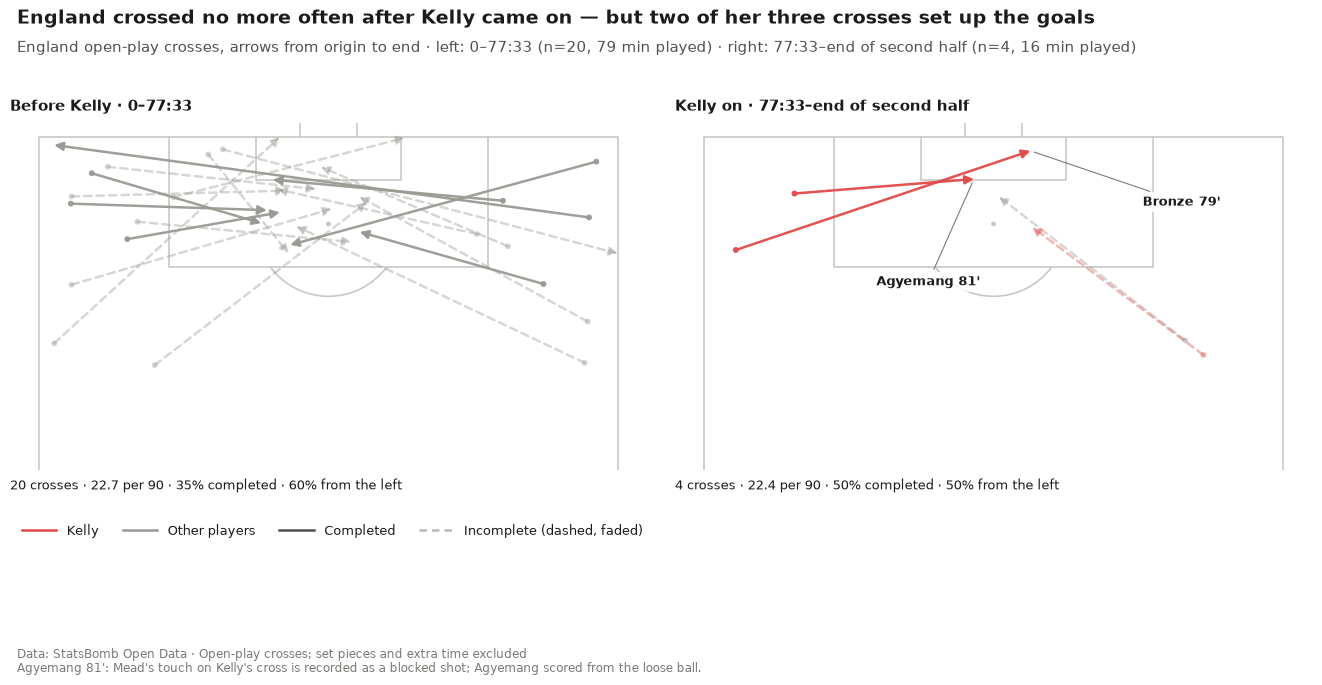

In [21]:
C = P.COLORS
KELLY_COLOR, OTHER_COLOR = P.TEAM_COLORS["England"], C["neutral"]
COMPLETE_ALPHA, INCOMPLETE_ALPHA = 0.95, 0.4
ARROW_LW = 1.8

fig = plt.figure(figsize=(14, 7))
H4_RECTS = {"before": (0.035, 0.275, 0.455, 0.56), "after": (0.51, 0.275, 0.455, 0.56)}
# Crop each half-pitch to the final yards (same crop in both panels); every open-play cross starts beyond it.
H4_CROP_X = 74
assert open_crosses.cross_x.min() > H4_CROP_X + 2
H4_HEADS = {"before": "Before Kelly · 0–77:33", "after": "Kelly on · 77:33–end of second half"}
h4_drawn = {}
for w in ["before", "after"]:
    pitch, ax = P.add_pitch(fig, H4_RECTS[w], vertical=True, half=True, pad_top=2, pad_bottom=60 - H4_CROP_X)
    c = open_crosses[open_crosses.h4_window == w]
    arrows = {}
    for i, r in c.sort_values("player").iterrows():
        kelly = r.player == "Chloe Kelly"
        arrows[i] = pitch.annotate(
            "", xy=(r.cross_end_x, r.cross_end_y), xytext=(r.cross_x, r.cross_y), ax=ax,
            arrowprops=dict(arrowstyle="-|>,head_length=0.5,head_width=0.25", lw=ARROW_LW,
                            color=KELLY_COLOR if kelly else OTHER_COLOR,
                            alpha=COMPLETE_ALPHA if r.completed else INCOMPLETE_ALPHA,
                            linestyle="-" if r.completed else (0, (3, 2)), shrinkA=0, shrinkB=0),
            zorder=4 if kelly else 3,
        )
    pitch.scatter(c.cross_x, c.cross_y, ax=ax, s=18, zorder=5, linewidths=0,
                  c=[KELLY_COLOR if p == "Chloe Kelly" else OTHER_COLOR for p in c.player],
                  alpha=[COMPLETE_ALPHA if ok else INCOMPLETE_ALPHA for ok in c.completed])
    ev = h4_evidence.iloc[0 if w == "before" else 1]
    bbox = ax.get_position()
    fig.text(bbox.x0, bbox.y1 + 0.012, H4_HEADS[w], ha="left", va="bottom", fontsize=P.FONT_SIZES["subtitle"],
             fontweight="bold", color=C["text"])
    fig.text(bbox.x0, bbox.y0 - 0.012,
             f"{int(ev.crosses)} crosses · {ev.per_90:.1f} per 90 · {ev.completion_pct:.0f}% completed · "
             f"{ev.left_pct:.0f}% from the left", ha="left", va="top", fontsize=P.FONT_SIZES["label"] + 0.5,
             color=C["text"])
    h4_drawn[w] = dict(ax=ax, pitch=pitch, arrows=arrows)

# Goal deliveries: labels with leader lines, drawn once each (right panel).
GOAL_LABEL_POS = {"Bronze 79'": (111, 66), "Agyemang 81'": (100, 31)}  # (x, y) pitch coordinates
goal_labels = {}
for lab, i in assist_rows.items():
    r = h4_crosses.loc[i]
    pitch, ax = h4_drawn["after"]["pitch"], h4_drawn["after"]["ax"]
    goal_labels[lab] = pitch.annotate(
        lab, xy=(r.cross_end_x, r.cross_end_y), xytext=GOAL_LABEL_POS[lab], ax=ax, ha="center", va="center",
        fontsize=P.FONT_SIZES["label"] + 0.5, fontweight="bold", color=C["text"], zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", fc=C["background"], ec="none", alpha=0.9),
        arrowprops=dict(arrowstyle="-", color=C["text_muted"], lw=0.8, shrinkA=2, shrinkB=3),
    )

legend_handles = [
    Line2D([], [], color=KELLY_COLOR, lw=ARROW_LW, label="Kelly"),
    Line2D([], [], color=OTHER_COLOR, lw=ARROW_LW, label="Other players"),
    Line2D([], [], color=C["text_secondary"], lw=ARROW_LW, label="Completed"),
    Line2D([], [], color=C["text_secondary"], lw=ARROW_LW, ls=(0, (3, 2)), alpha=INCOMPLETE_ALPHA,
           label="Incomplete (dashed, faded)"),
]
legend_top = h4_drawn["before"]["ax"].get_position().y0 - 0.06
fig.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(0.035, legend_top), ncol=4, frameon=False,
           fontsize=P.FONT_SIZES["legend"], handlelength=2.6, columnspacing=1.8)

eb, ea = h4_evidence.iloc[0], h4_evidence.iloc[1]
P.add_title(
    fig, H4_TITLE,
    f"England open-play crosses, arrows from origin to end · left: 0–77:33 (n={int(eb.crosses)}, "
    f"{eb.minutes:.0f} min played) · right: 77:33–end of second half (n={int(ea.crosses)}, {ea.minutes:.0f} min played)",
)
P.add_footer(
    fig, "Data: StatsBomb Open Data · Open-play crosses; set pieces and extra time excluded",
    "Agyemang 81': Mead's touch on Kelly's cross is recorded as a blocked shot; Agyemang scored from the loose ball.",
)

In [22]:
# Built-in checks.
# 1) Arrow counts per panel = evidence table.
for w, k in [("before", 0), ("after", 1)]:
    n_arrows = len(h4_drawn[w]["arrows"])
    assert n_arrows == h4_evidence.iloc[k].crosses, w
    print(f"{w}: {n_arrows} arrows (evidence table: {int(h4_evidence.iloc[k].crosses)})")

# 2) Goal-assist deliveries plotted exactly once each (right panel only) and labelled once.
for lab, i in assist_rows.items():
    n_plotted = sum(i in h4_drawn[w]["arrows"] for w in h4_drawn)
    assert n_plotted == 1 and i in h4_drawn["after"]["arrows"], lab
    assert sum(t.get_text() == lab for t in fig.findobj(plt.Text)) == 1, lab
print("goal deliveries plotted and labelled once each:", ", ".join(assist_rows))

# 3) Same scale in both panels: identical data limits and identical axes size on the figure.
ax_b, ax_a = h4_drawn["before"]["ax"], h4_drawn["after"]["ax"]
fig.draw_without_rendering()
assert ax_b.get_xlim() == ax_a.get_xlim() and ax_b.get_ylim() == ax_a.get_ylim()
assert np.allclose(ax_b.get_position().size, ax_a.get_position().size)
print(f"same scale: limits x {ax_b.get_xlim()}, y {ax_b.get_ylim()}; axes size "
      f"{ax_b.get_position().width:.3f} x {ax_b.get_position().height:.3f} in both panels")

# 4) Orientation: England attack upwards, and left-flank crosses are drawn on the left half of the pitch.
pitch_b = h4_drawn["before"]["pitch"]
left = open_crosses[open_crosses.flank == "left"].iloc[0]
right = open_crosses[open_crosses.flank == "right"].iloc[0]


def screen(x, y):
    # Screen position of pitch point (x, y); a VerticalPitch plots y horizontally and x vertically.
    return ax_b.transData.transform((y, x))


assert screen(120, 40)[1] > screen(H4_CROP_X, 40)[1], "England should attack upwards"
assert screen(left.cross_x, left.cross_y)[0] < screen(right.cross_x, right.cross_y)[0],     "left flank should be drawn on the left"
print("orientation check passed: goal at the top, left-flank crosses on the left")

path = P.save_figure(fig, "04_h4_crosses")
print("saved:", d.relative_path(path))
plt.show()

before: 20 arrows (evidence table: 20)
after: 4 arrows (evidence table: 4)
goal deliveries plotted and labelled once each: Bronze 79', Agyemang 81'
same scale: limits x (np.float64(-4.0), np.float64(84.0)), y (np.float64(74.0), np.float64(122.0)); axes size 0.455 x 0.496 in both panels
orientation check passed: goal at the top, left-flank crosses on the left


saved: figures/04_h4_crosses.png
